In [2]:
import re
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

In [3]:
shots_map_df = pd.read_csv('../../data/raw/nba-api/shots_2025-26.csv')
defense_df = pd.read_csv('../../data/raw/nba-api/synergy_defense_2025-26.csv')
offense_df = pd.read_csv('../../data/raw/nba-api/synergy_offense_2025-26.csv')

In [4]:
ks = range(2, 13)
inertias, sils = [], []

poss = defense_df.pivot_table(index='PLAYER_NAME', columns='PLAY_TYPE', values='POSS',
                              aggfunc='sum', fill_value=0)
defense_freq = poss.div(poss.sum(axis=1), axis=0)
defense_freq = defense_freq[poss.sum(axis=1) >= 75]

print(poss)

for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(defense_freq)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(defense_freq, km.labels_))

# By whoever ended the play- so these values are going to be a little weird. (Zach Edey ends up
# guarding a lot of ball handlers even though hes a center due to mismatch)

PLAY_TYPE        Handoff  Isolation  OffScreen  PRBallHandler  PRRollMan  \
PLAYER_NAME                                                                
AJ Green              36         62         29            200         57   
AJ Johnson             0          0          0             19          0   
Aaron Gordon          20         39         18            111         30   
Aaron Holiday         22         19         19            108         28   
Aaron Nesmith         54         35         36            170         32   
...                  ...        ...        ...            ...        ...   
Zach Edey              0          0          0             71         13   
Zach LaVine           28         22         14            120         35   
Zeke Nnaji             0         30          0            112         25   
Ziaire Williams       24         47         32            130         55   
Zion Williamson       21         85         28            190         48   

PLAY_TYPE  

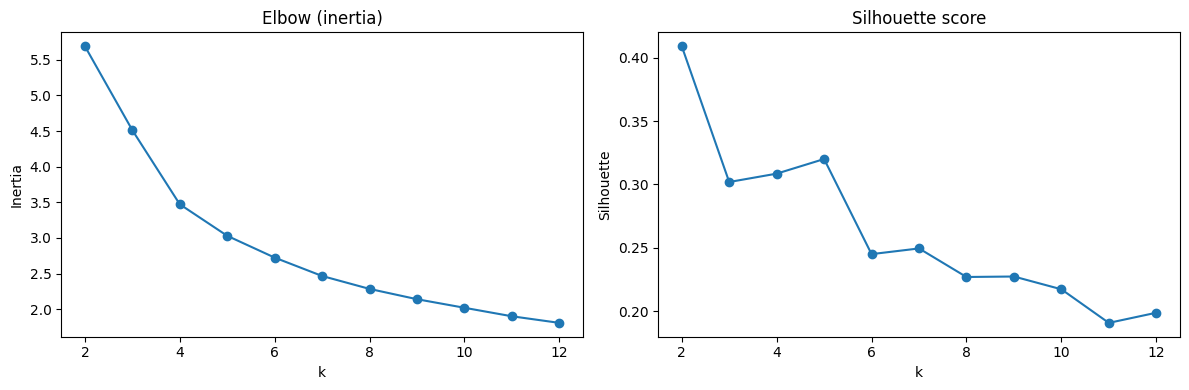

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(ks, inertias, marker='o')
ax[0].set_title('Elbow (inertia)')
ax[0].set_xlabel('k')
ax[0].set_ylabel('Inertia')

ax[1].plot(ks, sils, marker='o')
ax[1].set_title('Silhouette score')
ax[1].set_xlabel('k')
ax[1].set_ylabel('Silhouette')

plt.tight_layout()
plt.show()


PLAY_TYPE,Handoff,Isolation,OffScreen,PRBallHandler,PRRollMan,Postup,Spotup,n_players
0,0.00,0.09,0.01,0.51,0.15,0.03,0.22,75
1,0.05,0.10,0.04,0.31,0.08,0.04,0.38,161
2,0.14,0.23,0.12,0.00,0.39,0.13,0.00,3
3,0.07,0.09,0.06,0.38,0.08,0.04,0.28,158
4,0.14,0.10,0.11,0.00,0.12,0.08,0.44,4


0 ['Adem Bona', 'Al Horford', 'Alex Sarr', 'Alperen Sengun', 'Andre Drummond', 'Anthony Davis', 'Anthony Gill', 'Bam Adebayo', 'Bobby Portis Jr.', 'Branden Carlson']
1 ['AJ Green', 'Aaron Gordon', 'Aaron Wiggins', 'Ace Bailey', 'Alex Caruso', 'Andrew Wiggins', 'Anfernee Simons', 'Anthony Edwards', 'Asa Newell', 'Ayo Dosunmu']
2 ['Clint Capela', 'Precious Achiuwa', 'Russell Westbrook']
3 ['Aaron Holiday', 'Aaron Nesmith', 'Ajay Mitchell', 'Amen Thompson', 'Andrew Nembhard', 'Anthony Black', 'Ausar Thompson', 'Austin Reaves', 'Baylor Scheierman', 'Ben Sheppard']
4 ['CJ McCollum', 'Jamir Watkins', 'Tre Johnson', 'Will Riley']


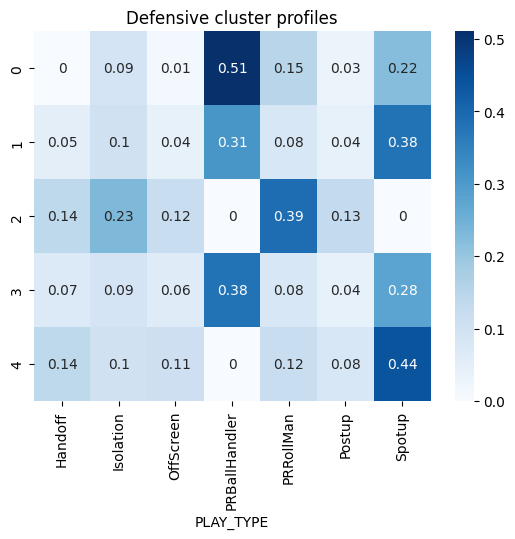

In [6]:
km = KMeans(n_clusters=5, n_init=20, random_state=42).fit(defense_freq)
defense_freq['Cluster'] = km.labels_

# What each cluster guards (average share per play type)
centers = pd.DataFrame(km.cluster_centers_, columns=defense_freq.columns.drop('Cluster')).round(2)
centers['n_players'] = defense_freq['Cluster'].value_counts().sort_index()
display(centers)

# Who's in each cluster
for c, grp in defense_freq.groupby('Cluster'):
    print(c, grp.index[:10].tolist())

sns.heatmap(centers.drop(columns='n_players'), annot=True, cmap='Blues')
plt.title('Defensive cluster profiles')
plt.show()

# I wonder if this chart more or less gives a good understanding of nba is constantly hunting for mismatches

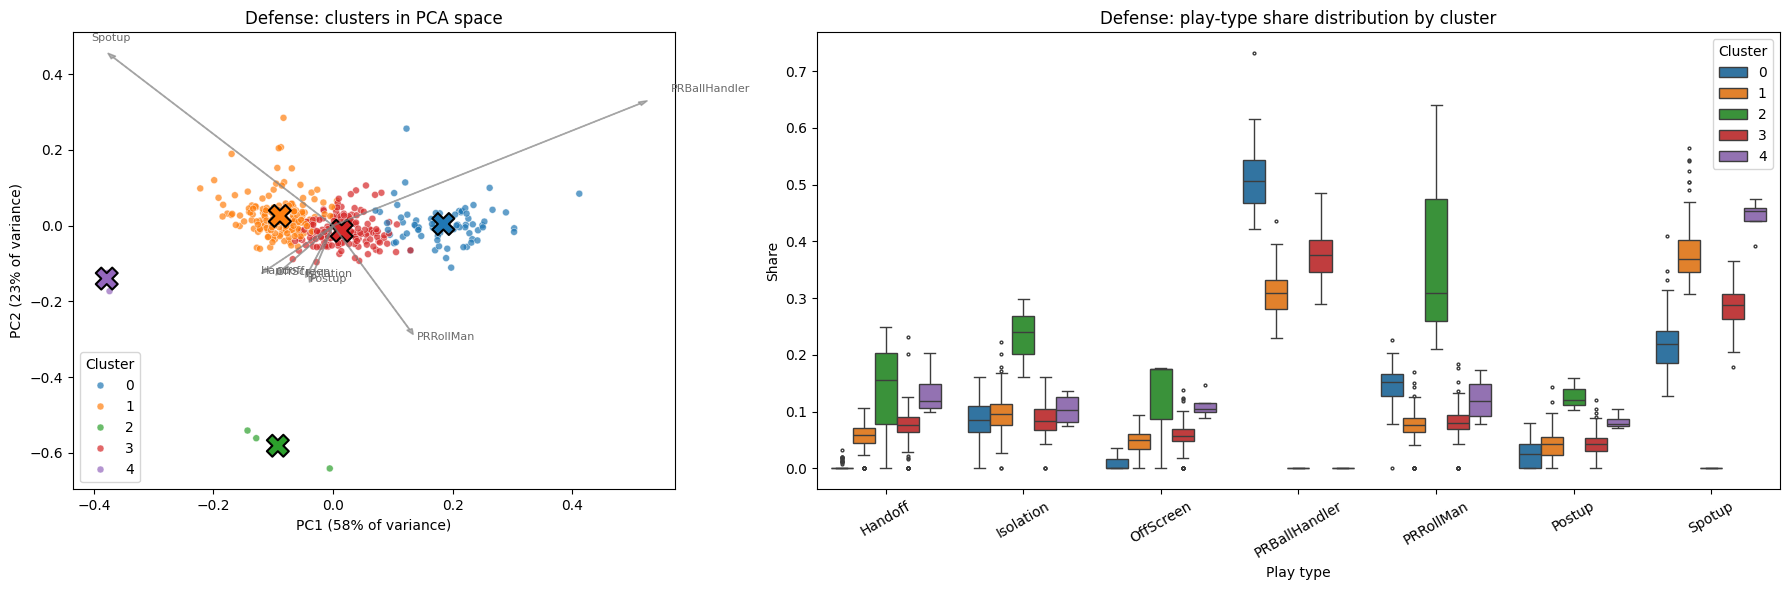

In [7]:
from sklearn.decomposition import PCA

def plot_clusters(freq, labels, title):
    feats = freq.drop(columns='Cluster', errors='ignore')
    labels = np.asarray(labels).astype(str)
    order = sorted(set(labels), key=int)
    palette = dict(zip(order, sns.color_palette('tab10', len(order))))

    fig, ax = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={'width_ratios': [1, 1.6]})

    # 2D view: project the play-type shares onto the first two principal components
    pca = PCA(n_components=2).fit(feats)
    xy = pca.transform(feats)
    sns.scatterplot(x=xy[:, 0], y=xy[:, 1], hue=labels, hue_order=order, palette=palette,
                    s=25, alpha=0.7, ax=ax[0])
    centroids = pca.transform(feats.groupby(labels).mean().loc[order])
    ax[0].scatter(centroids[:, 0], centroids[:, 1], marker='X', s=250,
                  c=[palette[c] for c in order], edgecolor='black', linewidth=1.5)

    # Arrows show which play types push players in each direction
    scale = np.abs(xy).max() / np.abs(pca.components_).max() * 0.8
    for name, (dx, dy) in zip(feats.columns, pca.components_.T):
        ax[0].arrow(0, 0, dx * scale, dy * scale, color='gray', alpha=0.6, head_width=0.01)
        ax[0].text(dx * scale * 1.1, dy * scale * 1.1, name, fontsize=8, color='dimgray')

    ev = pca.explained_variance_ratio_
    ax[0].set_xlabel(f'PC1 ({ev[0]:.0%} of variance)')
    ax[0].set_ylabel(f'PC2 ({ev[1]:.0%} of variance)')
    ax[0].set_title(f'{title}: clusters in PCA space')
    ax[0].legend(title='Cluster')

    # Distribution of each play-type share within each cluster
    long = feats.assign(Cluster=labels).melt(id_vars='Cluster', var_name='Play type', value_name='Share')
    sns.boxplot(data=long, x='Play type', y='Share', hue='Cluster', hue_order=order,
                palette=palette, fliersize=2, ax=ax[1])
    ax[1].set_title(f'{title}: play-type share distribution by cluster')
    ax[1].tick_params(axis='x', rotation=30)

    plt.tight_layout()
    plt.show()

plot_clusters(defense_freq, defense_freq['Cluster'], 'Defense')

In [ ]:
ks = range(2, 13)
inertias, sils = [], []

poss = offense_df.pivot_table(index='PLAYER_NAME', columns='PLAY_TYPE', values='POSS',
                              aggfunc='sum', fill_value=0)
offense_freq = poss.div(poss.sum(axis=1), axis=0)
offense_freq = offense_freq[poss.sum(axis=1) >= 75]

print(poss)

for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(offense_freq)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(offense_freq, km.labels_))


PLAY_TYPE        Cut  Handoff  Isolation  Misc  OffRebound  OffScreen  \
PLAYER_NAME                                                             
AJ Green          14       95          0    36           0         66   
AJ Johnson         0        0         21     0           0          0   
Aaron Gordon      66        0         69    32          32          0   
Aaron Holiday      0       11         13    14           0          0   
Aaron Nesmith     16       39         14    25          19        100   
...              ...      ...        ...   ...         ...        ...   
Zach Edey         19        0          0    15          18          0   
Zach LaVine       19       36         55    13           0         51   
Zeke Nnaji        38        0          0    18          21          0   
Ziaire Williams   34       60          0    22          12         11   
Zion Williamson  118       34        242    35          87         12   

PLAY_TYPE        PRBallHandler  PRRollMan  Postup 

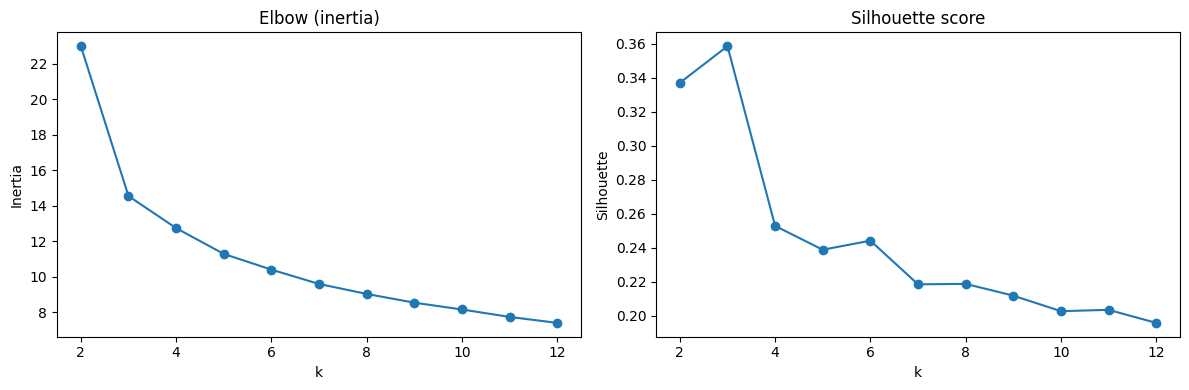

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(ks, inertias, marker='o')
ax[0].set_title('Elbow (inertia)')
ax[0].set_xlabel('k')
ax[0].set_ylabel('Inertia')

ax[1].plot(ks, sils, marker='o')
ax[1].set_title('Silhouette score')
ax[1].set_xlabel('k')
ax[1].set_ylabel('Silhouette')

plt.tight_layout()
plt.show()


PLAY_TYPE,Cut,Handoff,Isolation,Misc,OffRebound,OffScreen,PRBallHandler,PRRollMan,Postup,Spotup,Transition,n_players
0,0.03,0.07,0.05,0.05,0.02,0.05,0.19,0.02,0.00,0.30,0.21,97
1,0.14,0.01,0.01,0.07,0.09,0.01,0.01,0.15,0.04,0.30,0.17,52
2,0.25,0.00,0.01,0.11,0.22,-0.00,0.00,0.20,0.06,0.04,0.09,47
3,0.05,0.03,0.02,0.04,0.04,0.03,0.06,0.03,0.01,0.44,0.23,100
4,0.08,0.05,0.12,0.05,0.05,0.06,0.13,0.05,0.10,0.16,0.16,42
5,0.02,0.06,0.12,0.04,0.01,0.02,0.39,0.01,0.01,0.16,0.16,75


0 ['Aaron Holiday', 'Aaron Nesmith', 'Aaron Wiggins', 'Anthony Black', 'Ayo Dosunmu', 'Bilal Coulibaly', 'Blake Wesley', 'Bones Hyland', 'Brandin Podziemski', 'Brandon Miller']
1 ['Al Horford', 'Alex Sarr', 'Anthony Gill', 'Asa Newell', 'Bam Adebayo', 'Bobby Portis Jr.', 'Branden Carlson', 'Brook Lopez', 'Chet Holmgren', 'Christian Braun']
2 ['Adem Bona', 'Andre Drummond', 'Clint Capela', 'Daniel Gafford', "Day'Ron Sharpe", 'Deandre Ayton', 'Domantas Sabonis', 'Donovan Clingan', 'Drew Eubanks', 'Dwight Powell']
3 ['AJ Green', 'Alex Caruso', 'Andrew Wiggins', 'Baylor Scheierman', 'Ben Sheppard', 'Bryce McGowens', 'Buddy Hield', 'Caleb Martin', 'Carter Bryant', 'Daeqwon Plowden']
4 ['Aaron Gordon', 'Ace Bailey', 'Alperen Sengun', 'Amen Thompson', 'Anthony Davis', 'Anthony Edwards', 'Ausar Thompson', 'Brandon Ingram', 'Corey Kispert', 'DeMar DeRozan']
5 ['AJ Johnson', 'Ajay Mitchell', 'Andrew Nembhard', 'Anfernee Simons', 'Austin Reaves', 'Ben Saraf', 'Bennedict Mathurin', 'Bogdan Bogdano

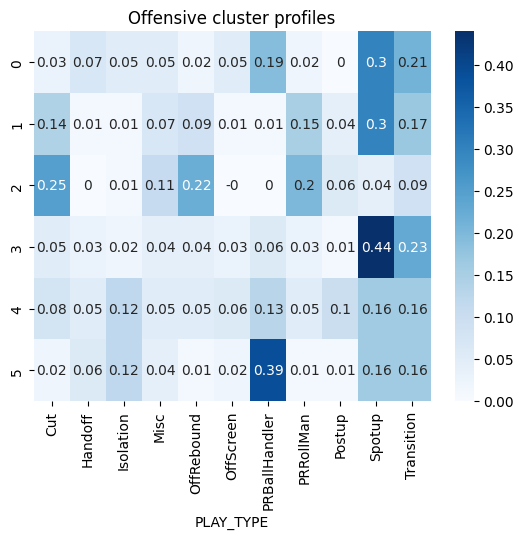

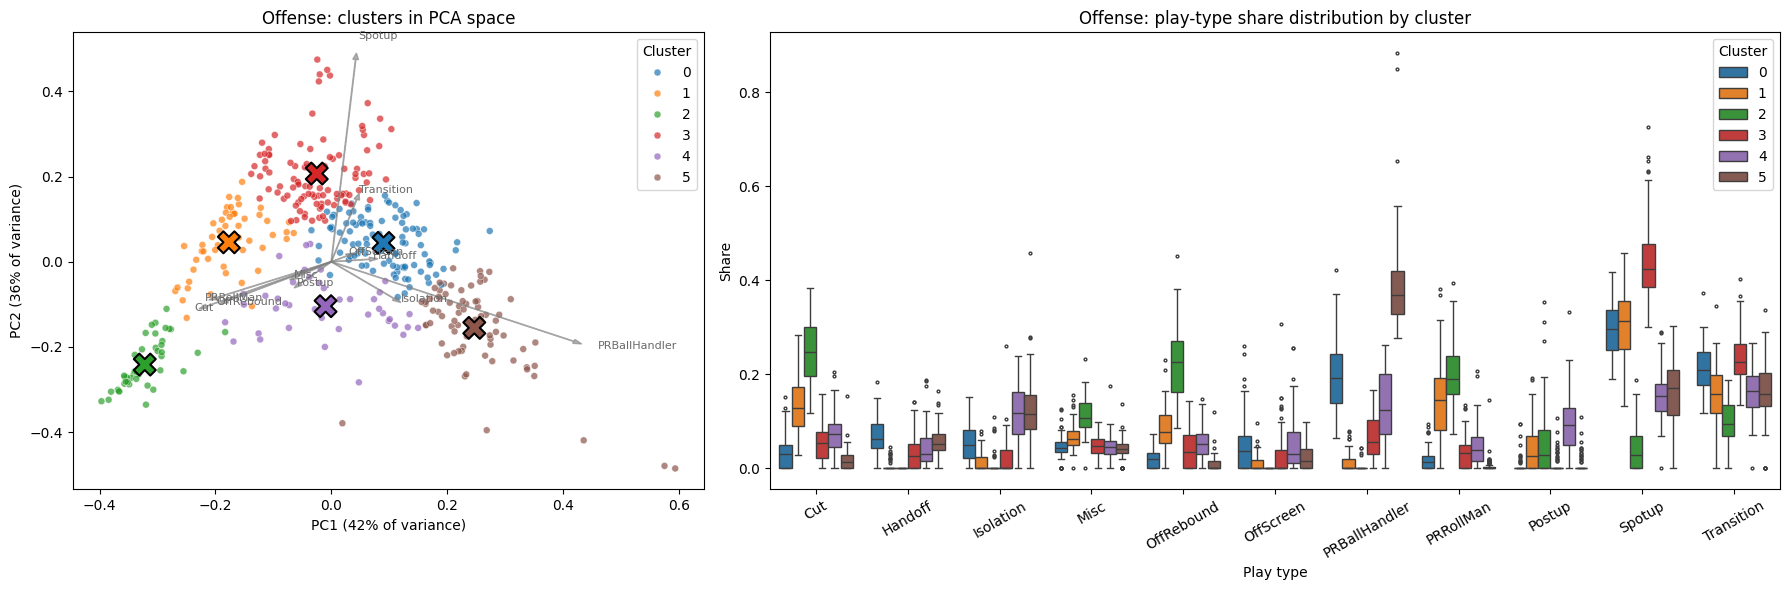

In [ ]:
km = KMeans(n_clusters=6, n_init=20, random_state=42).fit(offense_freq)
offense_freq['Cluster'] = km.labels_

# What each cluster runs (average share per play type)
centers = pd.DataFrame(km.cluster_centers_, columns=offense_freq.columns.drop('Cluster')).round(2)
centers['n_players'] = offense_freq['Cluster'].value_counts().sort_index()
display(centers)

# Who's in each cluster
for c, grp in offense_freq.groupby('Cluster'):
    print(c, grp.index[:10].tolist())

sns.heatmap(centers.drop(columns='n_players'), annot=True, cmap='Blues')
plt.title('Offensive cluster profiles')
plt.show()

plot_clusters(offense_freq, offense_freq['Cluster'], 'Offense')

# Silhouette peaks at k=3, but that's too coarse for archetypes; k=6 is a local bump with balanced sizes